## Import required libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from PIL import Image
import os
os.chdir('C:\\Users\\Saira Akram\\Desktop\\dataset22') #enter the path of your downloaded GTSRB dataset folder
from sklearn.model_selection import train_test_split
from keras.utils import to_categorical
from keras.models import Sequential, load_model
from keras.layers import Conv2D, MaxPool2D, Dense, Flatten, Dropout

## Store data, labels in the list

In [ ]:
data = []
labels = []
# We have 43 Classes
classes = 43
cur_path = os.getcwd()

In [ ]:
cur_path

'C:\\Users\\Saira Akram\\Desktop\\dataset22'

# Preprocess the images

In [ ]:
for i in range(classes):
    path = os.path.join(cur_path,'Train',str(i))
    images = os.listdir(path)
    for a in images:
        try:
            image = Image.open(path + '\\'+ a)
            image = image.resize((25,25)) # changes from 25,25
            image = np.array(image)
            data.append(image)
            labels.append(i)
        except Exception as e:
            print(e)

# Displays only one Image

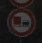

In [ ]:
image_path = ('C:\\Users\\Saira Akram\\Desktop\\dataset22\\Train\\10\\00010_00000_00011.png') # enter the path from your downloaded dataset
image_loaded = tf.keras.utils.load_img(image_path)
image_loaded

# Display multiple images of specified folder

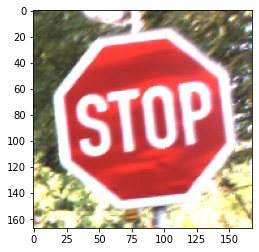

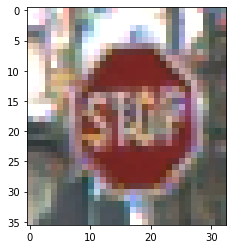

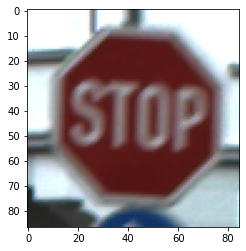

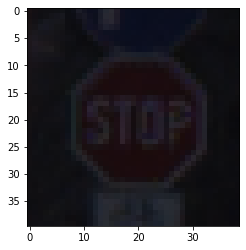

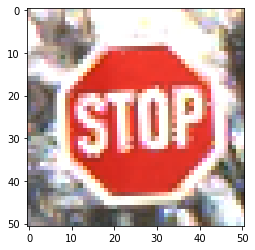

In [ ]:
import random
import matplotlib.image as mpimg
test_folder = (r'C:\\Users\\Saira Akram\\Desktop\\dataset22\\Train') #enter the path of your downloaded GTSRB dataset folder
for i in range(5):
    img_folder = (r'C:\\Users\\Saira Akram\\Desktop\\dataset22\\Train\\14') #enter the path of your downloaded GTSRB dataset folder
    file = random.choice(os.listdir(img_folder))
    image_path= os.path.join(img_folder, file)
    img=mpimg.imread(image_path)
    plt.imshow(img)
    plt.show()

## Converting lists into numpy arrays

In [ ]:
data = np.array(data)
labels = np.array(labels)

## Save Labels & Data for future use

In [ ]:
#os.mkdir('training')

np.save('./training/data',data)
np.save('./training/target',labels)

## Load data & Labels

In [ ]:
try:
    data=np.load('./training/data.npy')
    labels=np.load('./training/target.npy')
except Exception as e:
    print(e)

In [ ]:
print(data.shape, labels.shape)

(39209, 25, 25, 3) (39209,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data, labels, test_size=0.2, random_state=0)

In [ ]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(31367, 25, 25, 3) (7842, 25, 25, 3) (31367,) (7842,)


## Convert labels to onehot encoding

In [ ]:
y_train = to_categorical(y_train, 43)
y_test = to_categorical(y_test, 43)

## Now it's time to build the model

In [ ]:
try:
    model = Sequential()
    model.add(Conv2D(filters=32, kernel_size=(5,5), activation='relu', input_shape=X_train.shape[1:]))
    model.add(Conv2D(filters=32, kernel_size=(5,5), activation='relu'))
    model.add(MaxPool2D(pool_size=(2, 2)))
    model.add(Dropout(rate=0.25))
    model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
    model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
    model.add(MaxPool2D(pool_size=(2, 2)))
    model.add(Dropout(rate=0.25))
    model.add(Flatten())
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(rate=0.5))
# We have 43 classes that's why we have defined 43 in the dense
    model.add(Dense(43, activation='softmax'))

except Exception as e:
            print(e)


In [ ]:
#Compilation of the model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [ ]:
history = model.fit(X_train, y_train, batch_size=32, epochs=40, validation_data=(X_test, y_test))

Epoch 1/40
981/981 [==============================] - 126s 121ms/step - loss: 2.2126 - accuracy: 0.4306 - val_loss: 0.8349 - val_accuracy: 0.7970
Epoch 2/40
981/981 [==============================] - 111s 113ms/step - loss: 0.9741 - accuracy: 0.7071 - val_loss: 0.4092 - val_accuracy: 0.8930
Epoch 3/40
981/981 [==============================] - 113s 115ms/step - loss: 0.6540 - accuracy: 0.8031 - val_loss: 0.2792 - val_accuracy: 0.9217
Epoch 4/40
981/981 [==============================] - 109s 111ms/step - loss: 0.4938 - accuracy: 0.8520 - val_loss: 0.2824 - val_accuracy: 0.9134
Epoch 5/40
981/981 [==============================] - 109s 111ms/step - loss: 0.4303 - accuracy: 0.8753 - val_loss: 0.1348 - val_accuracy: 0.9612
Epoch 6/40
981/981 [==============================] - 110s 112ms/step - loss: 0.3473 - accuracy: 0.9017 - val_loss: 0.1382 - val_accuracy: 0.9601
Epoch 7/40
981/981 [==============================] - 110s 112ms/step - loss: 0.3107 - accuracy: 0.9109 - val_loss: 0.0846 -

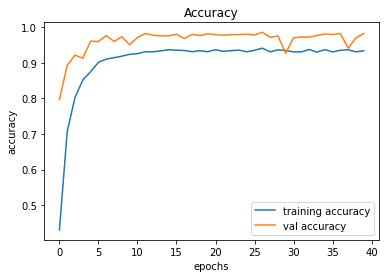

In [ ]:
# accuracy
plt.figure(0)
plt.plot(history.history['accuracy'], label='training accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')
plt.title('Accuracy')
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.legend()
plt.show()

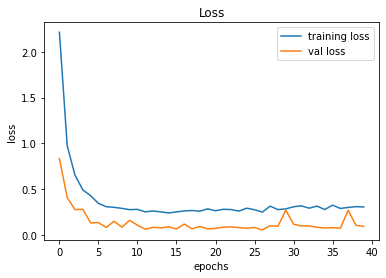

In [ ]:
# Loss
plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.title('Loss')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend()
plt.show()

In [ ]:
history.history?

## LEt's do testing on Test data

In [ ]:
X_test=0
def testing(testcsv):
    y_test = pd.read_csv(testcsv)
    label = y_test["ClassId"].values
    imgs = y_test["Path"].values
    data=[]
    for img in imgs:
        image = Image.open(img)
        image = image.resize((25,25))
        data.append(np.array(image))
    X_test=np.array(data)
    return X_test,label

In [ ]:
X_test, label = testing('Test.csv')

In [ ]:
try:
    Y_pred = np. argmax(model.predict(X_test),axis=1)
    Y_pred
except Exception as e:
            print(e)

395/395 [==============================] - 44s 26ms/step


## Accuracy with the test data

In [ ]:
from sklearn.metrics import accuracy_score
print(accuracy_score(label, Y_pred))

0.9425178147268408


## Save the model

In [ ]:
model.save("./training/TSR.keras") # changed from model.save("./training/TSR.h5")#

# Load the Model

In [ ]:
import os
os.chdir(r'C:\\Users\\Saira Akram\\Desktop\\dataset22') #enter the path of your downloaded GTSRB dataset folder
from keras.models import load_model
model = load_model('./training/TSR.keras') # chagned from model = load_model('./training/TSR.h5')

In [ ]:
# Classes of trafic signs
classes = { 0:'Speed limit (20km/h)',
            1:'Speed limit (30km/h)',
            2:'Speed limit (50km/h)',
            3:'Speed limit (60km/h)',
            4:'Speed limit (70km/h)',
            5:'Speed limit (80km/h)',
            6:'End of speed limit (80km/h)',
            7:'Speed limit (100km/h)',
            8:'Speed limit (120km/h)',
            9:'No passing',
            10:'No passing veh over 3.5 tons',
            11:'Right-of-way at intersection',
            12:'Priority road',
            13:'Yield',
            14:'Stop',
            15:'No vehicles',
            16:'Veh > 3.5 tons prohibited',
            17:'No entry',
            18:'General caution',
            19:'Dangerous curve left',
            20:'Dangerous curve right',
            21:'Double curve',
            22:'Bumpy road',
            23:'Slippery road',
            24:'Road narrows on the right',
            25:'Road work',
            26:'Traffic signals',
            27:'Pedestrians',
            28:'Children crossing',
            29:'Bicycles crossing',
            30:'Beware of ice/snow',
            31:'Wild animals crossing',
            32:'End speed + passing limits',
            33:'Turn right ahead',
            34:'Turn left ahead',
            35:'Ahead only',
            36:'Go straight or right',
            37:'Go straight or left',
            38:'Keep right',
            39:'Keep left',
            40:'Roundabout mandatory',
            41:'End of no passing',
            42:'End no passing veh > 3.5 tons' }

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
def test_on_img(img):
    data=[]
    image = Image.open(img)
    image = image.resize((25,25))
    data.append(np.array(image))
    X_test=np.array(data)
    Y_pred = np.argmax(model.predict(X_test),axis=1)
    return image,Y_pred

1/1 [==============================] - 4s 4s/step
Predicted traffic sign is:  Stop


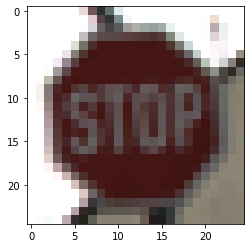

In [ ]:
plot,prediction = test_on_img(r'C:\\Users\\Saira Akram\\Desktop\\dataset22\\Test\\00093.png')#enter the path of your downloaded GTSRB dataset folder
s = [str(i) for i in prediction]
a = int("".join(s))
print("Predicted traffic sign is: ", classes[a])
plt.imshow(plot)
plt.show()

In [ ]:
prediction

array([14], dtype=int64)

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 21, 21, 32)        2432      
                                                                 
 conv2d_1 (Conv2D)           (None, 17, 17, 32)        25632     
                                                                 
 max_pooling2d (MaxPooling2D  (None, 8, 8, 32)         0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 8, 8, 32)          0         
                                                                 
 conv2d_2 (Conv2D)           (None, 6, 6, 64)          18496     
                                                                 
 conv2d_3 (Conv2D)           (None, 4, 4, 64)          36928     
                                                        

# F1 Score:

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(label,Y_pred, digits=4))
label

              precision    recall  f1-score   support

           0     0.9836    1.0000    0.9917        60
           1     0.9581    0.9833    0.9705       720
           2     0.9348    0.9560    0.9453       750
           3     0.8994    0.9333    0.9160       450
           4     0.9755    0.9636    0.9695       660
           5     0.8805    0.8889    0.8847       630
           6     1.0000    0.7133    0.8327       150
           7     0.9636    0.9400    0.9516       450
           8     0.9241    0.9733    0.9481       450
           9     0.9696    0.9979    0.9836       480
          10     0.9876    0.9682    0.9778       660
          11     0.9499    0.8571    0.9011       420
          12     0.9795    0.9710    0.9753       690
          13     0.9848    0.9931    0.9889       720
          14     0.9571    0.9926    0.9745       270
          15     0.9211    0.8333    0.8750       210
          16     0.9868    1.0000    0.9934       150
          17     0.9940    

array([16,  1, 38, ...,  6,  7, 10], dtype=int64)

# Confusion Matrix:

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix
from sklearn.utils.multiclass import unique_labels

In [ ]:
from sklearn.metrics import confusion_matrix
Y_pred


array([16,  1, 38, ..., 15,  7, 10], dtype=int64)

In [ ]:
from sklearn.metrics import confusion_matrix
confusion_matrix(label,Y_pred)

array([[ 60,   0,   0, ...,   0,   0,   0],
       [  1, 708,   8, ...,   1,   0,   0],
       [  0,   5, 717, ...,   0,   0,   0],
       ...,
       [  0,   1,   1, ...,  80,   0,   0],
       [  0,   0,   0, ...,   0,  54,   0],
       [  0,   0,   0, ...,   1,   3,  83]], dtype=int64)

In [ ]:
from sklearn.utils.multiclass import unique_labels
unique_labels(label)

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42], dtype=int64)

# Confusion Matrix Heat Map:

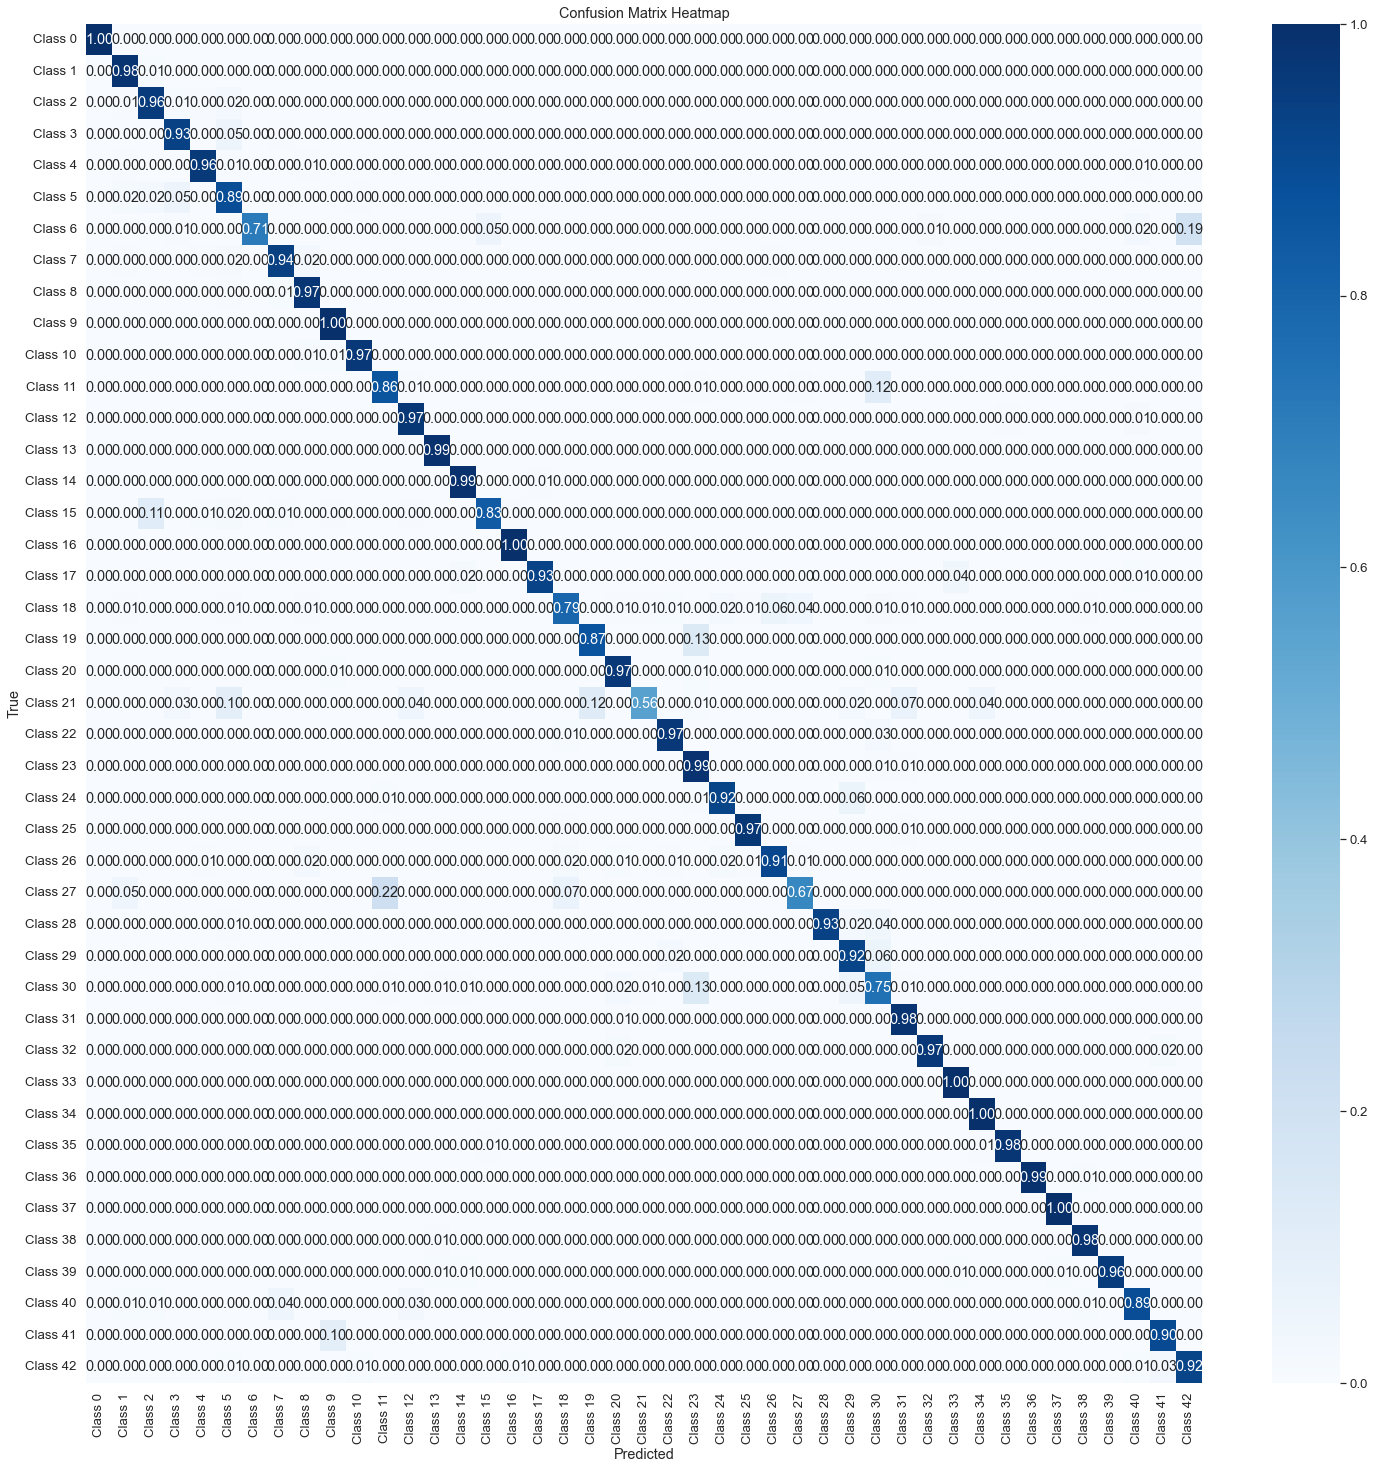

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate example data for demonstration purposes
np.random.seed(42)
num_classes = 43
y_true = np.random.randint(0, num_classes, size=100)
y_pred = np.random.randint(0, num_classes, size=100)

# Compute the confusion matrix
conf_matrix = confusion_matrix(label, Y_pred)

# Normalize the confusion matrix
conf_matrix_norm = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]

# Generate example class labels
class_labels = [f"Class {i}" for i in range(num_classes)]

# Create the heatmap
plt.figure(figsize=(25, 25))
sns.set(font_scale=1.2)
sns.heatmap(conf_matrix_norm, annot=True, cmap="Blues", fmt=".2f",
            xticklabels=class_labels, yticklabels=class_labels)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix Heatmap')
plt.show()

# Applying Data Augmentation to check accuracy drop (Robustness Check)

In [ ]:
import os
import numpy as np
from keras.models import load_model
from keras.preprocessing.image import ImageDataGenerator

# Load your model
model = load_model('./training/TSR.keras')

# Specify the input shape expected by your model
input_shape = (25, 25, 3)  # Update with your image dimensions

# Define data augmentation for the training dataset
datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Compile your model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Set batch size and number of epochs
batch_size = 32
epochs = 40

# Train the model
history = model.fit(datagen.flow(X_train, y_train, batch_size),
                    steps_per_epoch=len(X_train) // batch_size,
                    epochs=epochs)

# Evaluate the model on the test dataset
test_loss, test_accuracy = model.evaluate(X_train, y_train, verbose=0)
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

Epoch 1/40
980/980 [==============================] - 116s 111ms/step - loss: 3.7261 - accuracy: 0.0820
Epoch 2/40
980/980 [==============================] - 110s 112ms/step - loss: 3.2422 - accuracy: 0.1544
Epoch 3/40
980/980 [==============================] - 112s 114ms/step - loss: 2.8809 - accuracy: 0.2306
Epoch 4/40
980/980 [==============================] - 129s 131ms/step - loss: 2.5652 - accuracy: 0.2883
Epoch 5/40
980/980 [==============================] - 118s 120ms/step - loss: 2.3996 - accuracy: 0.3242
Epoch 6/40
980/980 [==============================] - 116s 118ms/step - loss: 2.2132 - accuracy: 0.3543
Epoch 7/40
980/980 [==============================] - 122s 124ms/step - loss: 2.1218 - accuracy: 0.3768
Epoch 8/40
980/980 [==============================] - 125s 128ms/step - loss: 2.0329 - accuracy: 0.4023
Epoch 9/40
980/980 [==============================] - 120s 116ms/step - loss: 1.9659 - accuracy: 0.4118
Epoch 10/40
980/980 [==============================] - 116s 112m

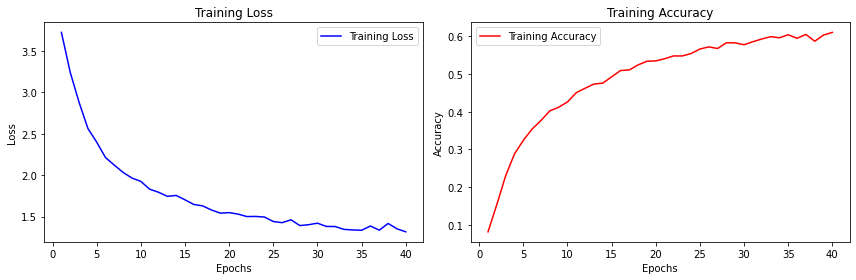

In [ ]:
import matplotlib.pyplot as plt

# Access training history
training_loss = history.history['loss']
training_accuracy = history.history['accuracy']

# Create a range of epochs for the x-axis
epochs_range = range(1, epochs + 1)

# Plot training loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, training_loss, 'b-', label='Training Loss')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot training accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, training_accuracy, 'r-', label='Training Accuracy')
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Show the plots
plt.tight_layout()
plt.show()